# Polynomial Regression Using Mini-batch Gradient Descent with Momentum

In this project, we use Polynomial Regression to predict car fuel efficiency (MPG) based on vehicle weight.

The model is trained using Mini-batch Gradient Descent with Momentum. This method updates the model weights using small batches of training samples instead of the entire dataset or one sample at a time.

The goal is to minimize prediction error and evaluate the model using MSE and R-squared (R²).

## 1. Polynomial Regression Model

Polynomial Regression extends Linear Regression by adding polynomial features to capture curved relationships between variables.

In this project, we use a polynomial model of degree 2:

$$
\hat{y} = w_0 + w_1x + w_2x^2
$$

Where:
- $x$: Car weight.
- $\hat{y}$: Predicted MPG.
- $w_0, w_1, w_2$: Model weights.

In [59]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uciml/autompg-dataset/auto-mpg.csv


In [60]:
import pandas as pd

df = pd.read_csv('/kaggle/input/datasets/uciml/autompg-dataset/auto-mpg.csv')

df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


## 2. Dataset Description

The Auto MPG dataset contains information about different cars, including their weight and fuel efficiency.

In this project:
- **Input Feature (X):** Weight
- **Target Variable (y):** MPG (Miles Per Gallon)

The goal is to predict the fuel efficiency of a car based on its weight.

In [61]:
print(df.shape)
print(df.info())

(398, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    object 
dtypes: float64(3), int64(4), object(2)
memory usage: 28.1+ KB
None


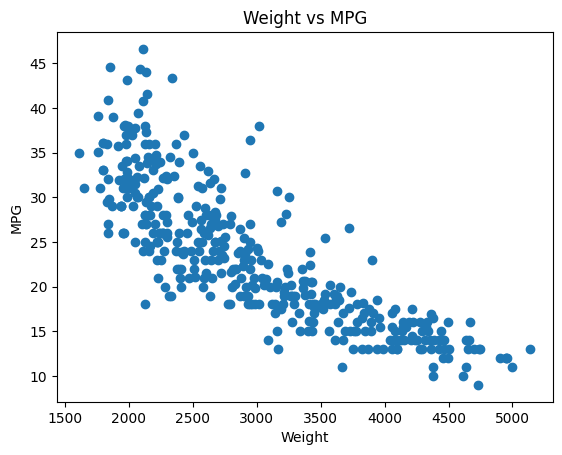

In [62]:
import matplotlib.pyplot as plt

plt.scatter(df['weight'], df['mpg'])
plt.xlabel('Weight')
plt.ylabel('MPG')
plt.title('Weight vs MPG')
plt.show()


In [63]:
X = df[['weight']].values
y = df['mpg'].values

print(X.shape)
print(y.shape)

(398, 1)
(398,)


In [64]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape)
print(X_test.shape)

(318, 1)
(80, 1)


In [65]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

print(X_train_poly.shape)
print(X_test_poly.shape)


(318, 3)
(80, 3)


In [66]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = X_train_poly.copy()
X_test_scaled = X_test_poly.copy()

X_train_scaled[:, 1:] = scaler.fit_transform(X_train_poly[:, 1:])
X_test_scaled[:, 1:] = scaler.transform(X_test_poly[:, 1:])

In [67]:
print(X_train_scaled.shape)
print(X_test_scaled.shape)

(318, 3)
(80, 3)


## 4. Mini-batch Gradient Descent with Momentum

Mini-batch Gradient Descent updates the model weights using small batches of training samples instead of the entire dataset or one sample at a time.

In this project, we use a batch size of 32 samples for each update.

Momentum uses information from previous updates to help accelerate the optimization process.

### Mathematical Formulas

The Gradient for each batch:

$$
g_t=\frac{2}{m}X_{\text{batch}}^T(X_{\text{batch}}w-y_{\text{batch}})
$$

The Momentum Update:

$$
v_t=\beta v_{t-1}+g_t
$$

The Weight Update:

$$
w_t=w_{t-1}-\alpha v_t
$$

### Hyperparameters
- Learning Rate = 0.001
- Momentum = 0.9
- Epochs = 1000
- Batch Size = 32

The model shuffles the training data at each epoch before creating the batches.

In [68]:
# Initialize parameters
weights = np.zeros(X_train_scaled.shape[1])
velocity = np.zeros(X_train_scaled.shape[1])

# Hyperparameters
learning_rate = 0.001
momentum = 0.9
epochs = 1000
batch_size = 32

n = len(y_train)
loss_history = []

# Training
for epoch in range(epochs):
    indices = np.random.permutation(n)
    X_shuffled = X_train_scaled[indices]
    y_shuffled = y_train[indices]

    for start in range(0, n, batch_size):
        end = start + batch_size
        X_batch = X_shuffled[start:end]
        y_batch = y_shuffled[start:end]

        predictions = X_batch @ weights
        error = predictions - y_batch

        gradient = (2 / len(y_batch)) * (X_batch.T @ error)

        velocity = momentum * velocity + gradient
        weights = weights - learning_rate * velocity

    predictions = X_train_scaled @ weights
    loss = np.mean((predictions - y_train) ** 2)
    loss_history.append(loss)

print("Final Training MSE:", loss_history[-1])

Final Training MSE: 18.554500071212573


## 5. Model Evaluation

After training the model, we evaluate its performance using two metrics:

### Mean Squared Error (MSE)

MSE measures the average squared difference between actual and predicted values.

$$
MSE=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

A lower MSE indicates better prediction accuracy.

### R-squared (R²)

R² measures how well the model explains the variation in the target variable.

A value closer to 1 indicates a better fit.

In [69]:
y_pred = X_test_scaled @ weights

test_mse = np.mean((y_test - y_pred) ** 2)

print("Test MSE:", test_mse)

Test MSE: 13.31152875060431


In [70]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)
print("R2 Score:", r2)

R2 Score: 0.7524193935440577


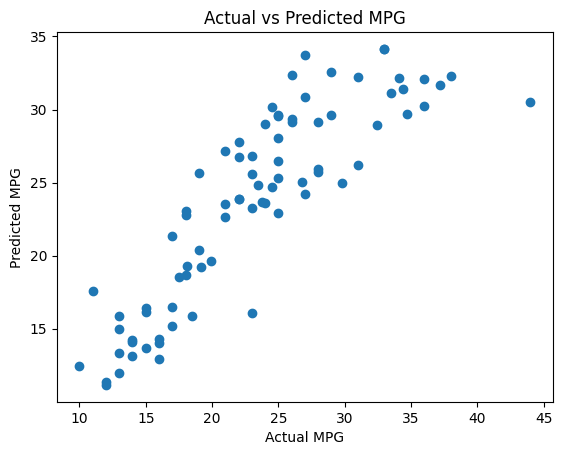

In [71]:
plt.scatter(y_test, y_pred)
plt.xlabel('Actual MPG')
plt.ylabel('Predicted MPG')
plt.title('Actual vs Predicted MPG')
plt.show()

## 6. Training Loss Curve

The following plot shows how the training MSE changes over the epochs.

A decreasing curve indicates that the model is learning and reducing its prediction error. When the curve becomes nearly stable, the model has reached convergence.

Text(0.5, 1.0, 'Mini-batch GD with Momentum - Loss Curve')

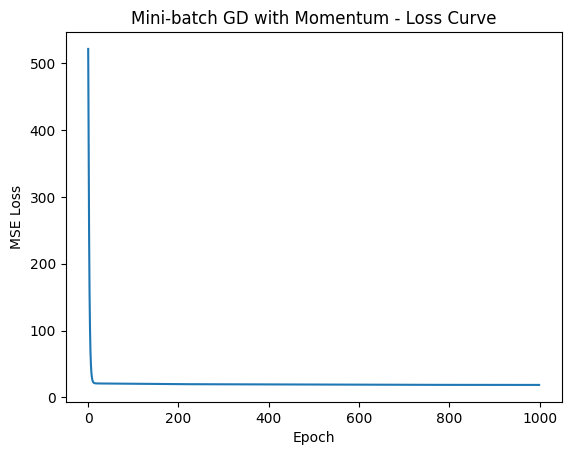

In [72]:
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Mini-batch GD with Momentum - Loss Curve")

## 7. Results and Conclusion

The model achieved the following results:

- Training MSE: 18.55
- Test MSE: 13.32
- R² Score: 0.7522

The R² score indicates that the model explains approximately 75.22% of the variation in MPG on the test data.

The results show that Mini-batch Gradient Descent with Momentum learned a relationship between car weight and fuel efficiency by updating the weights using batches of 32 samples.